In [56]:
# Basic Libraries
import numpy as np
import pandas as pd
import seaborn as sb
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

In [57]:
df = pd.read_csv('cardio_train.csv', sep=';')
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


# Data Cleaning

In [ ]:
# Convert age from days to years
df['age_years'] = round(df['age'] / 365.25, 2)

# Calculate BMI (weight in kg / height in meters squared)
df['bmi'] = round(df['weight'] / ((df['height'] / 100) ** 2), 2)

# Calculate Pulse Pressure
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']

# Clean Gender to binary (0 = Female, 1 = Male) for clearer SHAP interpretation
df['gender'] = df['gender'].map({1: 0, 2: 1})

# Filter physiologically impossible vitals, BMI, and Pulse Pressure
df_cleaned = df[
    (df['ap_hi'] >= 80) & (df['ap_hi'] <= 240) &
    (df['ap_lo'] >= 50) & (df['ap_lo'] <= 140) &
    (df['ap_hi'] > df['ap_lo']) &
    (df['pulse_pressure'] >= 20) & (df['pulse_pressure'] <= 120) & # Normal PP is around 40
    (df['height'] >= 130) & (df['height'] <= 210) &
    (df['weight'] >= 40) & (df['weight'] <= 180) &
    (df['bmi'] >= 15) & (df['bmi'] <= 55) 
].copy()

# Verify class balance post-cleaning
print("Class Balance after cleaning:")
print(df_cleaned['cardio'].value_counts(normalize=True).round(3))

features = [
    # Immutable Traits
    'age_years', 'gender', 
    # Physiological Vitals
    'bmi', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 
    # Lifestyle Choices
    'smoke', 'alco', 'active'
]
final_count = len(df_cleaned)
print(f"Final row count: {final_count}")
print(f"Rows dropped: {len(df) - final_count} ({round((len(df) - final_count)/len(df) * 100, 2)}%)")

# Display the summary of our new features
display(df_cleaned[['age_years', 'bmi', 'ap_hi', 'ap_lo', 'pulse_pressure']].describe().round(2))

Class Balance after cleaning:
cardio
0    0.505
1    0.495
Name: proportion, dtype: float64
Final row count: 68341
Rows dropped: 1659 (2.37%)


,age_years,bmi,ap_hi,ap_lo,pulse_pressure
count,68341.00,68341.00,68341.00,68341.00,68341.00
mean,53.29,27.43,126.70,81.31,45.39
std,6.76,5.12,16.61,9.38,11.53
min,29.56,15.04,80.00,50.00,20.00
25%,48.34,23.88,120.00,80.00,40.00
50%,53.94,26.35,120.00,80.00,40.00
75%,58.38,30.12,140.00,90.00,50.00
max,64.92,54.97,240.00,140.00,120.00


# Data Visualisation

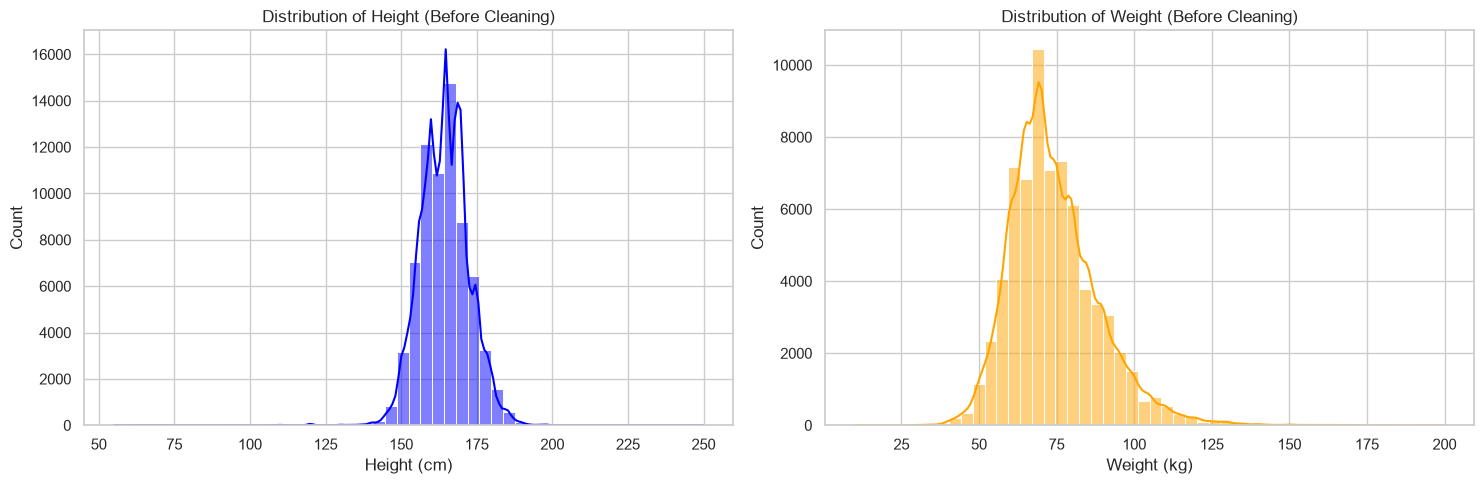

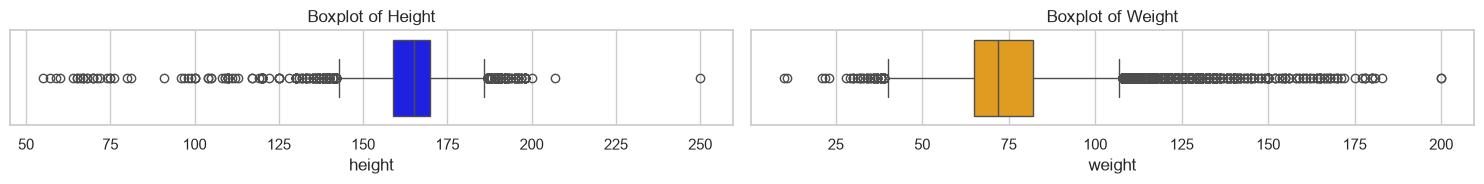

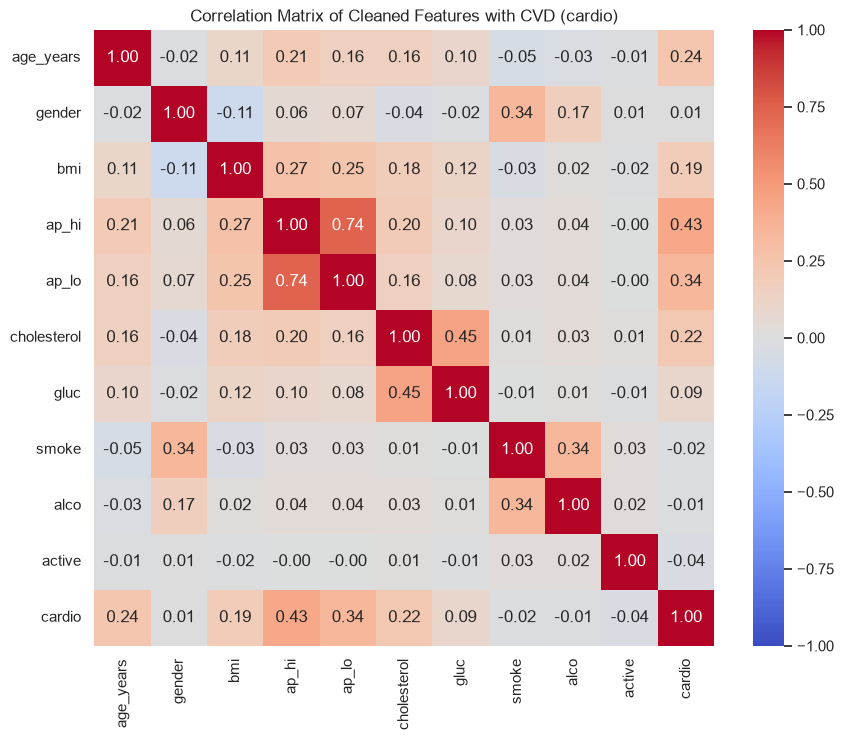

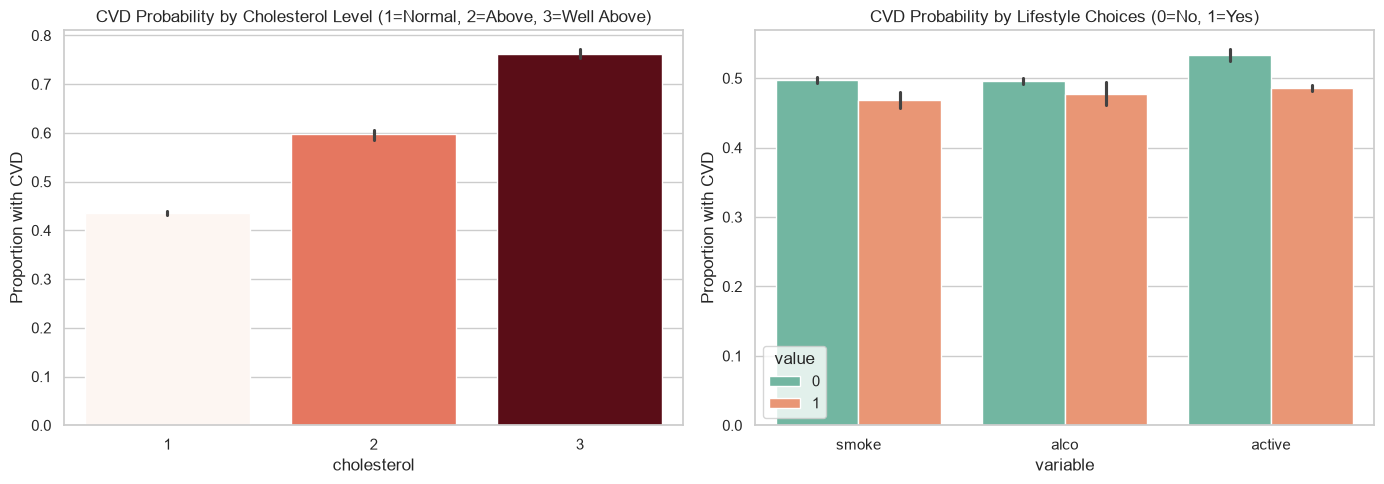

In [60]:
# Create a figure with two side-by-side plots
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Plot Height Histogram
sb.histplot(df['height'], bins=50, kde=True, ax=ax[0], color='blue')
ax[0].set_title('Distribution of Height (Before Cleaning)')
ax[0].set_xlabel('Height (cm)')
ax[0].set_ylabel('Count')

# Plot Weight Histogram
sb.histplot(df['weight'], bins=50, kde=True, ax=ax[1], color='orange')
ax[1].set_title('Distribution of Weight (Before Cleaning)')
ax[1].set_xlabel('Weight (kg)')
ax[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Create a figure for Boxplots
fig, ax = plt.subplots(1, 2, figsize=(15, 2))

sb.boxplot(x=df['height'], ax=ax[0], color='blue')
ax[0].set_title('Boxplot of Height')

sb.boxplot(x=df['weight'], ax=ax[1], color='orange')
ax[1].set_title('Boxplot of Weight')

plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(10, 8))
sb.heatmap(df_cleaned[features + ['cardio']].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Cleaned Features with CVD (cardio)')
plt.show()

# Visualizing Lifestyle vs Vitals Impact on CVD Rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Vitals: Cholesterol vs Cardio
sb.barplot(data=df_cleaned, x='cholesterol', y='cardio', hue='cholesterol', ax=axes[0], palette='Reds', legend=False)
axes[0].set_title('CVD Probability by Cholesterol Level (1=Normal, 2=Above, 3=Well Above)')
axes[0].set_ylabel('Proportion with CVD')

# Lifestyle: Smoking & Activity vs Cardio
lifestyle_melted = df_cleaned.melt(id_vars='cardio', value_vars=['smoke', 'alco', 'active'])
sb.barplot(data=lifestyle_melted, x='variable', y='cardio', hue='value', ax=axes[1], palette='Set2')
axes[1].set_title('CVD Probability by Lifestyle Choices (0=No, 1=Yes)')
axes[1].set_ylabel('Proportion with CVD')

plt.tight_layout()
plt.show()

# Baseline Model

In [61]:
# Define Features (X) and Target (y)
features = ['age_years', 'gender', 'height', 'weight', 'bmi',
            'ap_hi', 'ap_lo', 'pulse_pressure',
            'cholesterol', 'gluc', 'smoke', 'alco', 'active']

X = df_cleaned[features]
y = df_cleaned['cardio']

# Split the data into Training and Testing sets(80% of data for train, 20% for test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}\n")

# Build and Evaluate the Baseline Model (Decision Tree)
print("Baseline Model: Decision Tree")
dt_model = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_model.fit(X_train, y_train)

# Predict on the test set
dt_predictions = dt_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_predictions)

print(f"Decision Tree Accuracy: {dt_accuracy * 100:.2f}%\n")

Training data shape: (54672, 13)
Testing data shape: (13669, 13)

Baseline Model: Decision Tree
Decision Tree Accuracy: 73.25%



# Advanced Model

Advanced Model: Random Forest
Random Forest Accuracy: 73.63%

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.79      0.75      6946
           1       0.76      0.68      0.72      6723

    accuracy                           0.74     13669
   macro avg       0.74      0.74      0.74     13669
weighted avg       0.74      0.74      0.74     13669



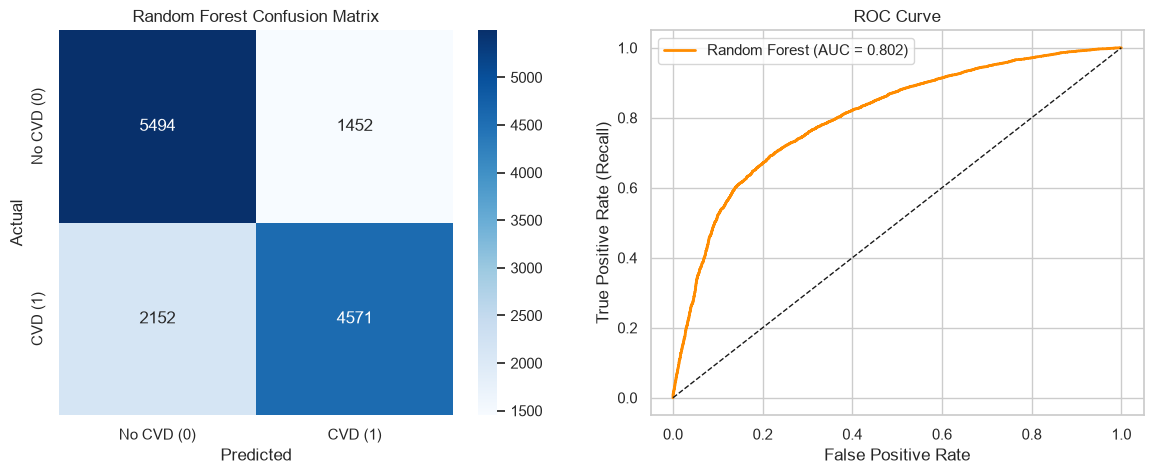

,Feature Group,Accuracy (%),ROC-AUC
0,"1. Lifestyle Only (Smoke, Alco, Active)",51.84,0.5197
1,"2. Immutable Only (Age, Gender)",59.08,0.6312
2,"3. Vitals Only (BP, BMI, Chol, Gluc)",72.84,0.7811
3,4. All Combined Features,73.63,0.8020


In [62]:
# Build and Evaluate the Advanced Model (Random Forest)
print("Advanced Model: Random Forest")
# We use 100 'trees' in this forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_model.fit(X_train, y_train)

# Predict on the test set
rf_predictions = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_predictions)

print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%\n")

# Detailed Performance Report for Random Forest
print("Random Forest Classification Report:")
print(classification_report(y_test, rf_predictions))

# Visual Confusion Matrix & ROC Curve
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, rf_predictions)
sb.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
           xticklabels=['No CVD (0)', 'CVD (1)'], yticklabels=['No CVD (0)', 'CVD (1)'])
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')
ax[0].set_title('Random Forest Confusion Matrix')

rf_probs = rf_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, rf_probs)
auc_score = roc_auc_score(y_test, rf_probs)
ax[1].plot(fpr, tpr, label=f"Random Forest (AUC = {auc_score:.3f})", color='darkorange', lw=2)
ax[1].plot([0, 1], [0, 1], 'k--', lw=1)
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate (Recall)')
ax[1].set_title('ROC Curve')
ax[1].legend()
plt.show()

# Comparing Predictive Power of Feature Groups
feature_groups = {
    '1. Lifestyle Only (Smoke, Alco, Active)': ['smoke', 'alco', 'active'],
    '2. Immutable Only (Age, Gender)': ['age_years', 'gender'],
    '3. Vitals Only (BP, BMI, Chol, Gluc)': ['ap_hi', 'ap_lo', 'bmi', 'cholesterol', 'gluc'],
    '4. All Combined Features': features
}

group_results = []
for group_name, cols in feature_groups.items():
    model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
    model.fit(X_train[cols], y_train)
    preds = model.predict(X_test[cols])
    probs = model.predict_proba(X_test[cols])[:, 1]
    group_results.append({
        'Feature Group': group_name,
        'Accuracy (%)': round(accuracy_score(y_test, preds) * 100, 2),
        'ROC-AUC': round(roc_auc_score(y_test, probs), 4)
    })

results_df = pd.DataFrame(group_results)
display(results_df)

# SHAP (SHapley Additive exPlanation)

SHAP Feature Importance (Bar Chart)


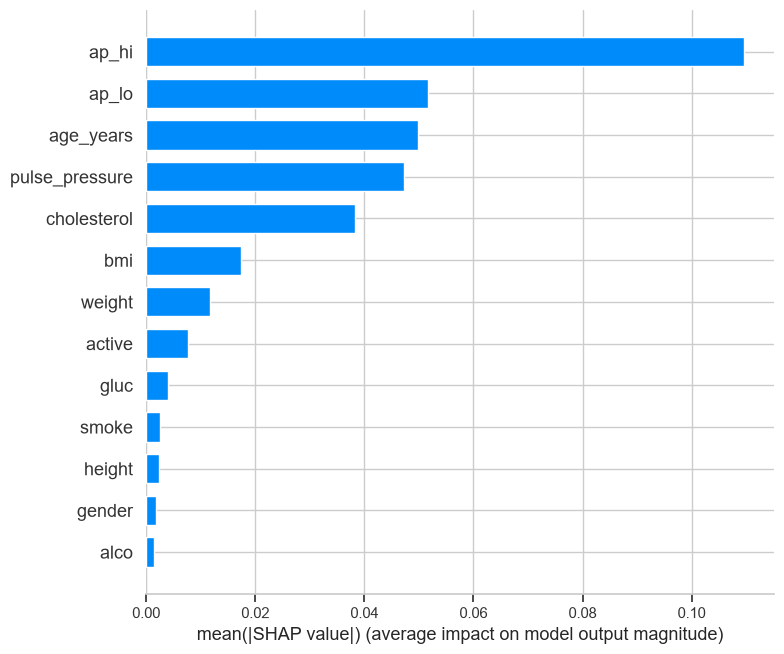

SHAP Detailed Summary Plot


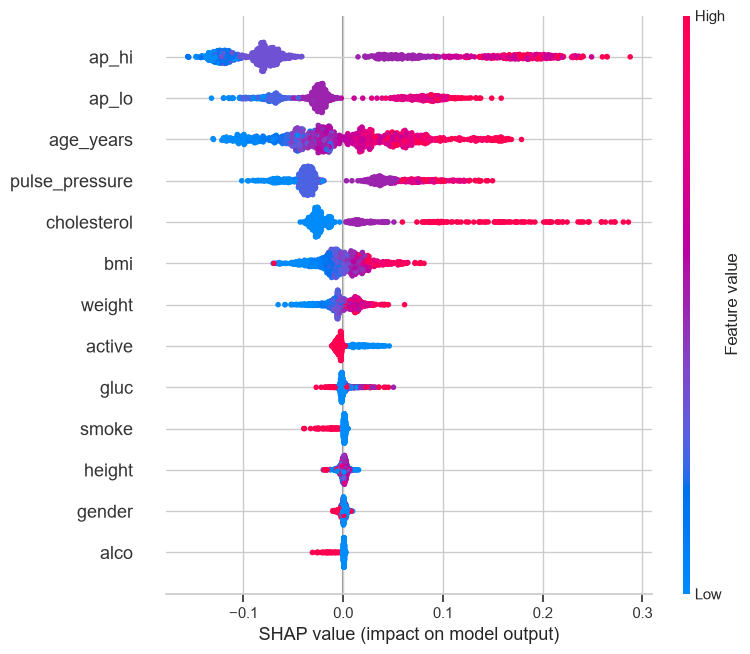

,Category,Mean_Abs_SHAP,Percentage_Share (%)
2,Physiological Vitals,0.280014,81.02
0,Immutable Traits,0.053971,15.62
1,Lifestyle Choices,0.011622,3.36


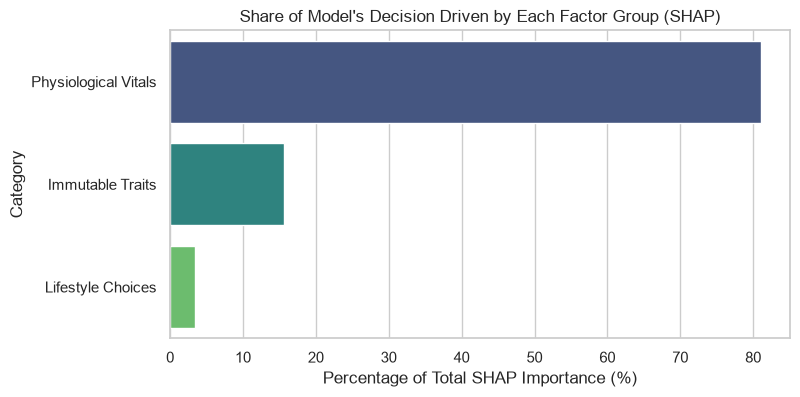

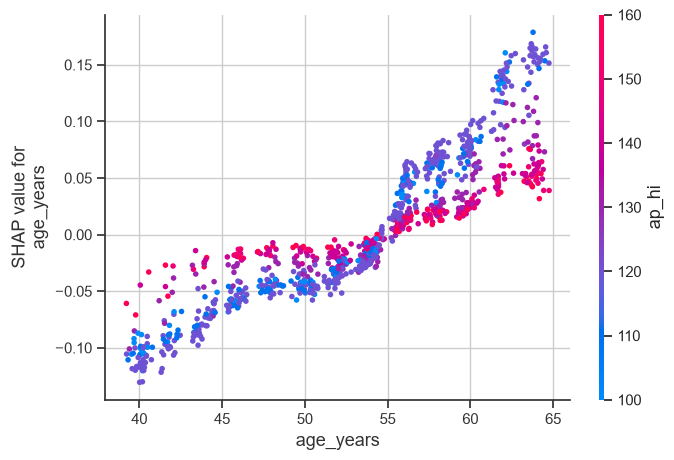

In [63]:
# Initialize the SHAP Explainer
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values (using a sample of 1000 to keep it fast)
X_test_sample = X_test.sample(n=1000, random_state=42)
shap_values = explainer.shap_values(X_test_sample)

# Handle different versions of the SHAP library
if isinstance(shap_values, list):
    # Older SHAP versions return a list of arrays
    shap_values_cvd = shap_values[1]
else:
    # Newer SHAP versions return a 3D numpy array: (samples, features, classes)
    # We want all samples (:), all features (:), and class 1 (index 1 for CVD)
    shap_values_cvd = shap_values[:, :, 1]

# Plot 1: Feature Importance Bar Chart
print("SHAP Feature Importance (Bar Chart)")
shap.summary_plot(shap_values_cvd, X_test_sample, plot_type="bar")

# Plot 2: Detailed SHAP Summary Plot
print("SHAP Detailed Summary Plot")
shap.summary_plot(shap_values_cvd, X_test_sample)

# Group SHAP values into the 3 Problem Statement Categories
mean_abs_shap = np.abs(shap_values_cvd).mean(axis=0)
shap_df = pd.DataFrame({'Feature': X_test_sample.columns, 'Mean_Abs_SHAP': mean_abs_shap})

category_map = {
    'age_years': 'Immutable Traits', 'gender': 'Immutable Traits', 'height': 'Immutable Traits',
    'ap_hi': 'Physiological Vitals', 'ap_lo': 'Physiological Vitals', 'pulse_pressure': 'Physiological Vitals',
    'bmi': 'Physiological Vitals', 'weight': 'Physiological Vitals', 'cholesterol': 'Physiological Vitals', 'gluc': 'Physiological Vitals',
    'smoke': 'Lifestyle Choices', 'alco': 'Lifestyle Choices', 'active': 'Lifestyle Choices'
}

shap_df['Category'] = shap_df['Feature'].map(category_map)
grouped_shap = shap_df.groupby('Category')['Mean_Abs_SHAP'].sum().reset_index()
grouped_shap['Percentage_Share (%)'] = (grouped_shap['Mean_Abs_SHAP'] / grouped_shap['Mean_Abs_SHAP'].sum() * 100).round(2)
grouped_shap = grouped_shap.sort_values(by='Percentage_Share (%)', ascending=False)

display(grouped_shap)

# Plot Grouped SHAP Contribution
plt.figure(figsize=(8, 4))
sb.barplot(data=grouped_shap, x='Percentage_Share (%)', y='Category', hue='Category', palette='viridis', legend=False)
plt.title("Share of Model's Decision Driven by Each Factor Group (SHAP)")
plt.xlabel("Percentage of Total SHAP Importance (%)")
plt.show()

# 2. SHAP Interaction / Dependence Plot
shap.dependence_plot("age_years", shap_values_cvd, X_test_sample, interaction_index="ap_hi")
